# Análisis ambiental y económico de la cuenca de Valdivia dentro del período 2008 a 2020 #

In [1]:
#Ubicación de los archivos para el análisis.
import os 
os.getcwd()

'C:\\Users\\danis\\Analisis cuenca de Valdivia 2008 a 2020'

## Limpieza y unificación de datos ##

In [2]:
import pandas as pd

In [3]:
#Carga de datos 
df_precipitaciones = pd.read_csv("Precipitaciones Valdivia.csv")
df_caudales = pd.read_csv("Rio Calle Calle desde 2008 al 2020.csv")
df_tarifa_anual = pd.read_csv("Tarifa agua media anual.csv", sep=";")

In [4]:
#Revisión de carga de datos correcta
df_precipitaciones.head

<bound method NDFrame.head of      agno   mes   dia   valor
0    2000     1     1    33.7
1    2000     2     1   213.4
2    2000     3     1    84.2
3    2000     4     1   179.9
4    2000     5     1   147.5
..    ...   ...   ...     ...
199  2024     8     1    68.4
200  2024     9     1   120.0
201  2024    10     1    15.6
202  2024    11     1    69.6
203  2024    12     1     7.8

[204 rows x 4 columns]>

In [5]:
df_caudales.head

<bound method NDFrame.head of       agno   mes   dia   valor
0     2007     3     8   150.0
1     2007     3     9   157.0
2     2007     3    10   154.0
3     2007     3    11   150.0
4     2007     3    12   156.0
...    ...   ...   ...     ...
4784  2020     6     1   229.9
4785  2020     6     2   233.0
4786  2020     6     3   230.8
4787  2020     6     4   220.5
4788  2020     6     5   213.0

[4789 rows x 4 columns]>

In [6]:
df_tarifa_anual.head

<bound method NDFrame.head of      N°              Empresa Tarifa Media Anual ($/m3) Unnamed: 3 Unnamed: 4  \
0   NaN                  NaN                      1989       1990       1991   
1   1.0           ESSAT S.A.                        86        158        190   
2   2.0  Aguas del Altiplano                       NaN        NaN        NaN   
3   3.0           ESSAN S.A.                        80        114        199   
4   4.0    Aguas Antofagasta                       NaN        NaN        NaN   
..  ...                  ...                       ...        ...        ...   
57  NaN                  NaN                       NaN        NaN        NaN   
58  NaN                  NaN                       NaN        NaN        NaN   
59  NaN                  NaN                       NaN        NaN        NaN   
60  NaN                  NaN                       NaN        NaN        NaN   
61  NaN                  NaN                       NaN        NaN        NaN   

   Unname

In [7]:
print(df_caudales.columns.tolist())

['agno', ' mes', ' dia', ' valor']


In [8]:
# 1. Creamos la columna 'fecha'  traduciendo las columnas
df_caudales['fecha'] = pd.to_datetime(
    df_caudales[['agno', ' mes', ' dia']].rename(columns={'agno': 'year', ' mes': 'month', ' dia': 'day'})
)

In [9]:
# 2. Limpiamos las columnas redundantes
df_caudales = df_caudales.drop(columns=['agno', ' mes', ' dia'])

In [10]:
#3. Verificamos
print("Primeras filas de Caudales:")
print(df_caudales.head())

Primeras filas de Caudales:
    valor      fecha
0   150.0 2007-03-08
1   157.0 2007-03-09
2   154.0 2007-03-10
3   150.0 2007-03-11
4   156.0 2007-03-12


In [11]:
# 1. Hacemos lo mismo con el DataFram de precipitaciones
df_precipitaciones['fecha'] = pd.to_datetime(
    df_precipitaciones[['agno', ' mes', ' dia']].rename(columns={'agno': 'year', ' mes': 'month', ' dia': 'day'})
)

In [12]:
df_precipitaciones = df_precipitaciones.drop(columns=['agno', ' mes', ' dia'])

In [13]:
print("Primeras filas de Precipitaciones:")
print(df_precipitaciones.head())

Primeras filas de Precipitaciones:
    valor      fecha
0    33.7 2000-01-01
1   213.4 2000-02-01
2    84.2 2000-03-01
3   179.9 2000-04-01
4   147.5 2000-05-01


In [14]:
# 1. Filtramos para quedarnos solo con la fila de Aguas Décima
df_aguas_decima = df_tarifa_anual[df_tarifa_anual['Empresa'] == 'Aguas Décima']

In [15]:
# 2. Usamos "melt" para transformar los años de columnas a filas
# id_vars: son las columnas que NO queremos derretir (las que dejamos fijas)
# var_name: el nombre que le daremos a la nueva columna que guardará los años
# value_name: el nombre que le daremos a la columna que guardará el precio de la tarifa
df_largo = df_aguas_decima.melt(
    id_vars=['Empresa'], 
    var_name='año', 
    value_name='tarifa'
)

In [16]:
print(df_tarifa_anual.columns.tolist())

['N°', 'Empresa', 'Tarifa Media Anual ($/m3)', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Unnamed: 17', 'Unnamed: 18', 'Unnamed: 19', 'Unnamed: 20', 'Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25', 'Unnamed: 26', 'Unnamed: 27', 'Unnamed: 28', 'Unnamed: 29', 'Unnamed: 30', 'Unnamed: 31', 'Unnamed: 32', 'Unnamed: 33', 'Unnamed: 34', 'Unnamed: 35', 'Unnamed: 36', 'Unnamed: 37']


In [17]:
print(df_tarifa_anual.head(5))

    N°              Empresa Tarifa Media Anual ($/m3) Unnamed: 3 Unnamed: 4  \
0  NaN                  NaN                      1989       1990       1991   
1  1.0           ESSAT S.A.                        86        158        190   
2  2.0  Aguas del Altiplano                       NaN        NaN        NaN   
3  3.0           ESSAN S.A.                        80        114        199   
4  4.0    Aguas Antofagasta                       NaN        NaN        NaN   

  Unnamed: 5 Unnamed: 6 Unnamed: 7 Unnamed: 8 Unnamed: 9  ... Unnamed: 28  \
0       1992       1993       1994       1995       1996  ...        2015   
1        230        262        342        401        547  ...         NaN   
2        NaN        NaN        NaN        NaN        NaN  ...       1.626   
3        236        272        476        515        782  ...         NaN   
4        NaN        NaN        NaN        NaN        NaN  ...       2.607   

  Unnamed: 29 Unnamed: 30 Unnamed: 31 Unnamed: 32 Unnamed: 33 

In [18]:
# 1. Extraemos los años que están atrapados en la fila 0 (desde la tercera columna en adelante)
años = df_tarifa_anual.iloc[0, 2:].astype(str).tolist()

# Limpiamos los años por si Python les agregó un decimal al leerlos (ej. '1989.0' -> '1989')
años = [año.replace('.0', '') for año in años]

# 2. Renombramos TODAS las columnas de la tabla. 
# Mantenemos 'N°' y 'Empresa', y agregamos la lista de años.
df_tarifa_anual.columns = ['N°', 'Empresa'] + años

# 3. Eliminamos la fila 0 (que ya usamos) y reiniciamos el orden de la tabla
df_tarifa_anual = df_tarifa_anual.drop(0).reset_index(drop=True)

# 4. Verificamos que el problema esté solucionado
print(df_tarifa_anual.head(3))

    N°              Empresa 1989 1990 1991 1992 1993 1994 1995 1996  ...  \
0  1.0           ESSAT S.A.   86  158  190  230  262  342  401  547  ...   
1  2.0  Aguas del Altiplano  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  ...   
2  3.0           ESSAN S.A.   80  114  199  236  272  476  515  782  ...   

    2015   2016   2017   2018   2019   2020   2021   2022   2023   2024  
0    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN  
1  1.626  1.576  1.676  1.725  1.775  1.882  1.907  2.251  2.395  2.703  
2    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN  

[3 rows x 38 columns]


In [19]:
# 1. Filtramos para quedarnos solo con la fila de Aguas Décima
df_aguas_decima = df_tarifa_anual[df_tarifa_anual['Empresa'] == 'Aguas Décima']

# 2. Hacemos el melt. Como ahora las columnas SÍ son los años, usamos directamente la lista desde 2008 hasta 2020.
columnas_años = ['2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020']

df_largo = df_aguas_decima.melt(
    id_vars=['Empresa'], 
    value_vars=columnas_años, 
    var_name='año', 
    value_name='tarifa'
)

# 3. Convertimos a fecha y limpiamos
df_largo['fecha'] = pd.to_datetime(df_largo['año'], format='%Y')
df_largo = df_largo.drop(columns=['año'])

print("¡Tabla lista para el análisis!")
print(df_largo.head())

¡Tabla lista para el análisis!
        Empresa tarifa      fecha
0  Aguas Décima    906 2008-01-01
1  Aguas Décima    969 2009-01-01
2  Aguas Décima    930 2010-01-01
3  Aguas Décima    944 2011-01-01
4  Aguas Décima    982 2012-01-01


In [20]:
# 1. Unimos Precipitaciones y Caudales
df_clima = pd.merge(df_precipitaciones, df_caudales, on='fecha', how='inner', suffixes=('_precip', '_caudal'))

In [21]:
# 2. Sumamos la tabla de Tarifas Anuales (df_largo)
df_compilado_valdivia = pd.merge(df_clima, df_largo, on='fecha', how='inner')

In [22]:
# 3. Renombramos columnas para claridad
df_compilado_valdivia = df_compilado_valdivia.rename(columns={
    'valor_precip': 'precipitacion_mm',
    'valor_caudal': 'caudal_m3_s',
    'tarifa': 'tarifa_aguas_decima'
})

In [23]:
# 4. Revisión final
print(df_compilado_valdivia.info())
print(df_compilado_valdivia.head())

<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0    valor_precip        8 non-null      float64       
 1   fecha                8 non-null      datetime64[us]
 2    valor_caudal        8 non-null      float64       
 3   Empresa              8 non-null      str           
 4   tarifa_aguas_decima  8 non-null      str           
dtypes: datetime64[us](1), float64(2), str(2)
memory usage: 586.0 bytes
None
    valor_precip      fecha   valor_caudal       Empresa tarifa_aguas_decima
0           39.2 2008-01-01          270.0  Aguas Décima                 906
1           20.2 2009-01-01          169.0  Aguas Décima                 969
2           39.0 2010-01-01          439.0  Aguas Décima                 930
3           41.8 2011-01-01          314.0  Aguas Décima                 944
4           68.4 2012-01-01          182.0  Aguas 

In [24]:
# 1. Limpiamos cualquier símbolo y convertimos la columna a float64
df_compilado_valdivia['tarifa_aguas_decima'] = (
    df_compilado_valdivia['tarifa_aguas_decima']
    .astype(str)
    .str.replace('$', '', regex=False)    # Quitamos el signo $ si existe
    .str.replace('.', '', regex=False)    # Eliminamos el punto de los miles (ej: 1.576 -> 1576)
    .str.replace(',', '.', regex=False)   # Si hay comas decimales, las adaptamos al formato Python
    .astype(float)                        # Finalmente, convertimos el texto limpio a float64
)

In [25]:
# 2. Revisamos que el cambio haya sido exitoso
print(df_compilado_valdivia.info())

<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0    valor_precip        8 non-null      float64       
 1   fecha                8 non-null      datetime64[us]
 2    valor_caudal        8 non-null      float64       
 3   Empresa              8 non-null      str           
 4   tarifa_aguas_decima  8 non-null      float64       
dtypes: datetime64[us](1), float64(3), str(1)
memory usage: 557.0 bytes
None


## Unificación de datos y Análisis de tendencia historica ##

In [26]:
print(df_compilado_valdivia.head(10))

    valor_precip      fecha   valor_caudal       Empresa  tarifa_aguas_decima
0           39.2 2008-01-01          270.0  Aguas Décima                906.0
1           20.2 2009-01-01          169.0  Aguas Décima                969.0
2           39.0 2010-01-01          439.0  Aguas Décima                930.0
3           41.8 2011-01-01          314.0  Aguas Décima                944.0
4           68.4 2012-01-01          182.0  Aguas Décima                982.0
5           44.7 2013-01-01          634.0  Aguas Décima                998.0
6           96.1 2014-01-01          165.0  Aguas Décima               1080.0
7            0.0 2015-01-01          194.0  Aguas Décima               1146.0


In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

In [28]:
# 1. Extraemos el año de tu columna de fecha para agrupar los datos
df_compilado_valdivia['año'] = df_compilado_valdivia['fecha'].dt.year

In [29]:
# 2. Calculamos el promedio anual para ver la tendencia macro (sin el ruido de los meses)
df_tendencia = df_compilado_valdivia.groupby('año').mean(numeric_only=True).reset_index()

In [30]:
# 1. Quitamos los espacios invisibles al principio y al final de todos los nombres de columnas
df_compilado_valdivia.columns = df_compilado_valdivia.columns.str.strip()

# 2. Aplicamos el cambio de nombre ahora que los espacios desaparecieron
df_compilado_valdivia = df_compilado_valdivia.rename(columns={
    'valor_precip': 'precipitacion_mm',
    'valor_caudal': 'caudal_m3_s',
    'tarifa': 'tarifa_aguas_decima' # Por si acaso
})

# 3. Volvemos a calcular la tabla de tendencia anual 
df_tendencia = df_compilado_valdivia.groupby('año').mean(numeric_only=True).reset_index()

# 4. Imprimimos los nombres de las columnas para verificar el éxito
print(df_tendencia.columns.tolist())

['año', 'precipitacion_mm', 'caudal_m3_s', 'tarifa_aguas_decima']


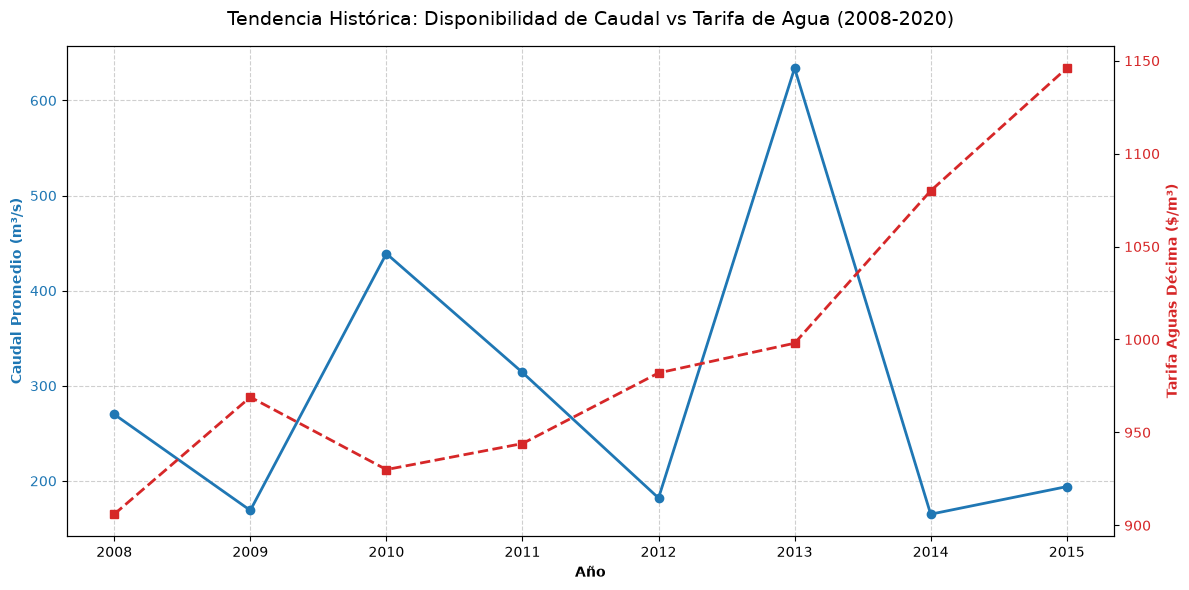

In [31]:

# 3. Configuramos el lienzo del gráfico
fig, ax1 = plt.subplots(figsize=(12, 6))

# --- Eje Izquierdo: Disponibilidad Hídrica (Caudal) ---
color_agua = '#1f77b4' # Azul
ax1.set_xlabel('Año', fontweight='bold')
ax1.set_ylabel('Caudal Promedio (m³/s)', color=color_agua, fontweight='bold')
ax1.plot(df_tendencia['año'], df_tendencia['caudal_m3_s'], color=color_agua, marker='o', linewidth=2, label='Caudal')
ax1.tick_params(axis='y', labelcolor=color_agua)
ax1.grid(True, linestyle='--', alpha=0.6)

# --- Eje Derecho: Impacto Económico (Tarifa) ---
ax2 = ax1.twinx()  # Esta es la función clave para crear el segundo eje Y
color_dinero = '#d62728' # Rojo
ax2.set_ylabel('Tarifa Aguas Décima ($/m³)', color=color_dinero, fontweight='bold')
ax2.plot(df_tendencia['año'], df_tendencia['tarifa_aguas_decima'], color=color_dinero, marker='s', linestyle='--', linewidth=2, label='Tarifa')
ax2.tick_params(axis='y', labelcolor=color_dinero)

# 4. Título y ajustes finales
plt.title('Tendencia Histórica: Disponibilidad de Caudal vs Tarifa de Agua (2008-2020)', fontsize=14, pad=15)
fig.tight_layout() # Evita que los textos se corten en los bordes
plt.show()

En el siguiente gráfico realizado no se puede ver una relación directa entre el caudal y la tarifa media anual, aunque si se puede ver una ligera variación en los mismos periodos de tiempo entre los caudales más grandes y los cobros un poco más bajo en el consumo de agua, aunque el periodo de tiempo es demasiado limitado como para asegurar que tengan que ver uno con el otro.

## Medias Moviles y Suavizados de tendencias ##

In [32]:
# 1. Calculamos la media móvil de 3 años para suavizar las curvas
# El parámetro min_periods=1 evita que los primeros años queden en blanco (NaN)
df_tendencia['caudal_movil_3'] = df_tendencia['caudal_m3_s'].rolling(window=3, min_periods=1).mean()
df_tendencia['tarifa_movil_3'] = df_tendencia['tarifa_aguas_decima'].rolling(window=3, min_periods=1).mean()

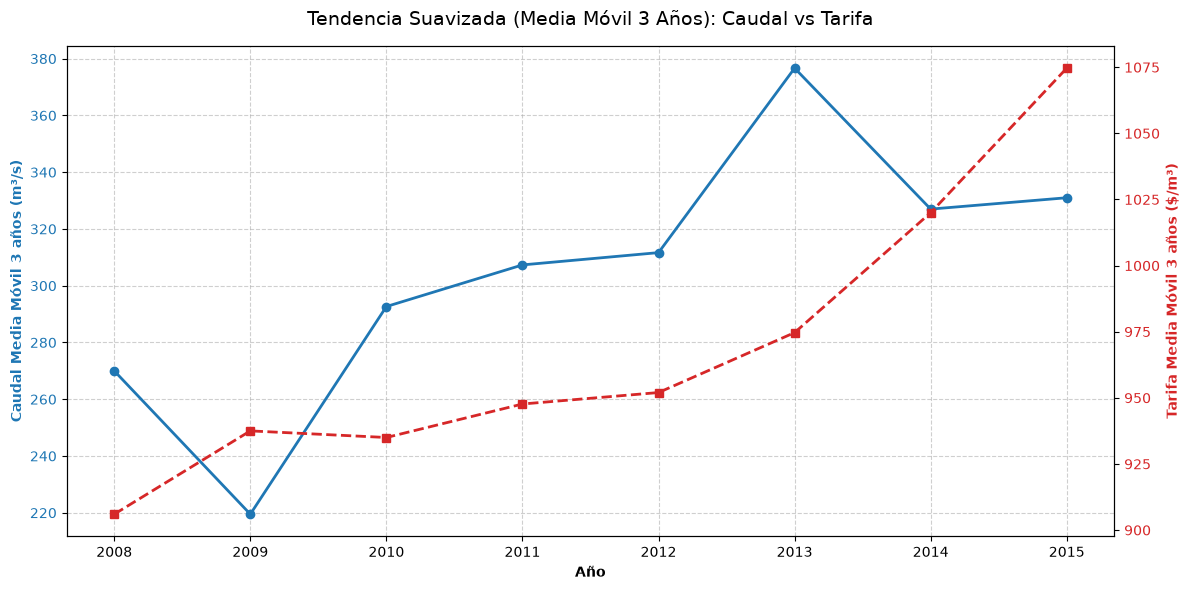

In [33]:
# 2. Configuramos el nuevo gráfico de Doble Eje con los datos suavizados
fig, ax1 = plt.subplots(figsize=(12, 6))

# --- Eje 1 (Izquierdo): Caudal Suavizado ---
color_agua = '#1f77b4'
ax1.set_xlabel('Año', fontweight='bold')
ax1.set_ylabel('Caudal Media Móvil 3 años (m³/s)', color=color_agua, fontweight='bold')
ax1.plot(df_tendencia['año'], df_tendencia['caudal_movil_3'], color=color_agua, marker='o', linewidth=2, label='Caudal')
ax1.tick_params(axis='y', labelcolor=color_agua)
ax1.grid(True, linestyle='--', alpha=0.6)

# --- Eje 2 (Derecho): Tarifa Suavizada ---
ax2 = ax1.twinx()
color_dinero = '#d62728'
ax2.set_ylabel('Tarifa Media Móvil 3 años ($/m³)', color=color_dinero, fontweight='bold')
ax2.plot(df_tendencia['año'], df_tendencia['tarifa_movil_3'], color=color_dinero, marker='s', linestyle='--', linewidth=2, label='Tarifa')
ax2.tick_params(axis='y', labelcolor=color_dinero)

# 3. Ajustes visuales
plt.title('Tendencia Suavizada (Media Móvil 3 Años): Caudal vs Tarifa', fontsize=14, pad=15)
fig.tight_layout()
plt.show()

Tanto en este gráfico como en el anterior se ve una tendencia al alza de las tarifas anuales del servicio de agua. Mientras que se identifica una baja muy brusca en el caudal durante el año 2009 y una alza igualmente brusca durante el 2013. Sigue sin identificarse correlaciones evidentes entre ambos valores